# Reproducibility / How to Run

This notebook was developed in Google Colab.

### Required input files
Upload the following files to the Colab session before running the notebook:

- `opa_properties_public (1).csv`
- `ACSDT5Y2024.B19013-Data.csv`
- `ACSDT5Y2024.B25064-Data.csv`
- `ACSDT5Y2024.B25003-Data.csv`
- `MORTGAGE30US.csv`

The 2024 Census tract geographic file is downloaded directly from the U.S. Census Bureau within the notebook.

### Running the notebook
1. Upload the required CSV files listed above.
2. Run the notebook cells from top to bottom in order.
3. The notebook cleans and merges the datasets, performs exploratory analysis, trains and evaluates the models, and creates the files needed for deployment.
4. Some Random Forest training cells may take several minutes to complete.

## Data Sources

- [Philadelphia Properties and Assessment History — OpenDataPhilly](https://opendataphilly.org/datasets/philadelphia-properties-and-assessment-history/)
- [U.S. Census Bureau ACS 2024 5-Year — B19013 Median Household Income](https://data.census.gov/table/ACSDT5Y2024.B19013)
- [U.S. Census Bureau ACS 2024 5-Year — B25064 Median Gross Rent](https://data.census.gov/table/ACSDT5Y2024.B25064)
- [U.S. Census Bureau ACS 2024 5-Year — B25003 Tenure](https://data.census.gov/table/ACSDT5Y2024.B25003)
- [U.S. Census Bureau TIGER/Line 2024 Census Tracts](https://www2.census.gov/geo/tiger/TIGER2024/TRACT/)
- [FRED — MORTGAGE30US: 30-Year Fixed Rate Mortgage Average](https://fred.stlouisfed.org/series/MORTGAGE30US)

## Project Links

- Live Prediction Website: https://phillyprice.streamlit.app

In [2]:
%pip install -q geopandas shapely pyproj requests joblib

In [3]:
from google.colab import files
files.upload()
!ls

Saving opa_properties_public (1).csv to opa_properties_public (1).csv
Saving MORTGAGE30US.csv to MORTGAGE30US.csv
Saving ACSDT5Y2024.B25064-Data.csv to ACSDT5Y2024.B25064-Data.csv
Saving ACSDT5Y2024.B25003-Data.csv to ACSDT5Y2024.B25003-Data.csv
Saving ACSDT5Y2024.B19013-Data.csv to ACSDT5Y2024.B19013-Data.csv
 ACSDT5Y2024.B19013-Data.csv   MORTGAGE30US.csv
 ACSDT5Y2024.B25003-Data.csv  'opa_properties_public (1).csv'
 ACSDT5Y2024.B25064-Data.csv   sample_data


#Cleaning and Merging

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("opa_properties_public (1).csv", low_memory=False)

print("Original rows:", df.shape[0])
print("Original columns:", df.shape[1])

important_cols = [
    "sale_price",
    "sale_date",
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "interior_condition",
    "year_built",
    "zip_code",
    "census_tract",
    "category_code_description",
    "shape"
]

df[important_cols].head()

Original rows: 583689
Original columns: 78


,sale_price,sale_date,total_livable_area,number_of_bedrooms,number_of_bathrooms,interior_condition,year_built,zip_code,census_tract,category_code_description,shape
0,107700.0,2026-08-20 04:00:00+00,1250.0,3.0,1.0,4.0,1925.0,19138.0,247.0,SINGLE FAMILY,SRID=2272;POINT(2692662.50363951 269906.248965...
1,2.0,2026-08-12 04:00:00+00,1260.0,3.0,1.0,4.0,1950.0,19149.0,314.0,SINGLE FAMILY,SRID=2272;POINT(2718815.18313553 270108.688393...
2,0.0,2026-08-21 04:00:00+00,1008.0,3.0,1.0,4.0,1920.0,19139.0,95.0,SINGLE FAMILY,SRID=2272;POINT(2672395.44193875 240378.463803...
3,209999.0,2026-08-12 04:00:00+00,812.0,3.0,1.0,4.0,1920.0,19148.0,372.0,SINGLE FAMILY,SRID=2272;POINT(2694908.14176572 221830.64115653)
4,243500.0,2026-08-03 04:00:00+00,1166.0,3.0,1.0,4.0,1925.0,19149.0,315.0,SINGLE FAMILY,SRID=2272;POINT(2724122.81423569 268018.918963...


In [5]:
df["category_code_description"].value_counts().head(15)

,count
category_code_description,
SINGLE FAMILY,463006
MULTI FAMILY,41451
VACANT LAND,39594
MIXED USE,14164
COMMERCIAL,12503
APARTMENTS > 4 UNITS,4102
INDUSTRIAL,3836
VACANT LAND - RESIDENTIAL,2307
GARAGE - RESIDENTIAL,1165


In [6]:
missing = df[important_cols].isna().sum()

pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2)
})

,missing_count,missing_percent
sale_price,2354,0.40
sale_date,2330,0.40
total_livable_area,42406,7.27
number_of_bedrooms,81144,13.90
number_of_bathrooms,86753,14.86
interior_condition,42755,7.32
year_built,42406,7.27
zip_code,137,0.02
census_tract,139,0.02
category_code_description,30,0.01


In [7]:
# Keep only single-family residential properties
df_clean = df[df["category_code_description"] == "SINGLE FAMILY"].copy()

print("Rows before filtering:", len(df))
print("Single-family rows:", len(df_clean))

Rows before filtering: 583689
Single-family rows: 463006


In [8]:
model_cols = [
    "sale_price",
    "sale_date",
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "interior_condition",
    "year_built",
    "zip_code",
    "census_tract",
    "shape"
]

df_clean = df_clean[model_cols].copy()

df_clean.head()

,sale_price,sale_date,total_livable_area,number_of_bedrooms,number_of_bathrooms,interior_condition,year_built,zip_code,census_tract,shape
0,107700.0,2026-08-20 04:00:00+00,1250.0,3.0,1.0,4.0,1925.0,19138.0,247.0,SRID=2272;POINT(2692662.50363951 269906.248965...
1,2.0,2026-08-12 04:00:00+00,1260.0,3.0,1.0,4.0,1950.0,19149.0,314.0,SRID=2272;POINT(2718815.18313553 270108.688393...
2,0.0,2026-08-21 04:00:00+00,1008.0,3.0,1.0,4.0,1920.0,19139.0,95.0,SRID=2272;POINT(2672395.44193875 240378.463803...
3,209999.0,2026-08-12 04:00:00+00,812.0,3.0,1.0,4.0,1920.0,19148.0,372.0,SRID=2272;POINT(2694908.14176572 221830.64115653)
4,243500.0,2026-08-03 04:00:00+00,1166.0,3.0,1.0,4.0,1925.0,19149.0,315.0,SRID=2272;POINT(2724122.81423569 268018.918963...


In [9]:
missing_single = df_clean.isna().sum()

pd.DataFrame({
    "missing_count": missing_single,
    "missing_percent": (missing_single / len(df_clean) * 100).round(2)
})

,missing_count,missing_percent
sale_price,1217,0.26
sale_date,1207,0.26
total_livable_area,45,0.01
number_of_bedrooms,600,0.13
number_of_bathrooms,5264,1.14
interior_condition,78,0.02
year_built,45,0.01
zip_code,8,0.00
census_tract,9,0.00
shape,8,0.00


In [10]:
df_clean["sale_price"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,sale_price
count,4.617890e+05
mean,3.253208e+05
std,1.717380e+07
min,0.000000e+00
1%,1.000000e+00
5%,1.000000e+00
10%,1.000000e+00
25%,1.000000e+00
50%,6.700000e+04
75%,1.950000e+05


In [11]:
print("Sale price <= $1:", (df_clean["sale_price"] <= 1).sum())
print("Sale price <= $100:", (df_clean["sale_price"] <= 100).sum())
print("Sale price <= $1,000:", (df_clean["sale_price"] <= 1000).sum())
print("Sale price <= $10,000:", (df_clean["sale_price"] <= 10000).sum())

Sale price <= $1: 118782
Sale price <= $100: 127383
Sale price <= $1,000: 128535
Sale price <= $10,000: 144083


In [12]:
# Check how sale prices are distributed across ranges
price_ranges = pd.cut(
    df_clean["sale_price"],
    bins=[-1, 1, 100, 1000, 10000, 25000, 50000, 100000,
          250000, 500000, 1000000, 2000000, float("inf")],
    labels=[
        "$0-$1",
        "$1-$100",
        "$100-$1K",
        "$1K-$10K",
        "$10K-$25K",
        "$25K-$50K",
        "$50K-$100K",
        "$100K-$250K",
        "$250K-$500K",
        "$500K-$1M",
        "$1M-$2M",
        "$2M+"
    ]
)

price_ranges.value_counts().sort_index()

,count
sale_price,
$0-$1,118782
$1-$100,8601
$100-$1K,1152
$1K-$10K,15548
$10K-$25K,24637
$25K-$50K,39331
$50K-$100K,62385
$100K-$250K,108244
$250K-$500K,59279


In [13]:
df_clean["sale_date"] = pd.to_datetime(df_clean["sale_date"], errors="coerce")

print("Earliest sale:", df_clean["sale_date"].min())
print("Latest sale:", df_clean["sale_date"].max())

df_clean["sale_date"].dt.year.value_counts().sort_index().tail(15)

Earliest sale: 1700-01-01 04:56:02+00:00
Latest sale: 2026-09-23 04:00:00+00:00


,count
sale_date,
2012.0,9885
2013.0,10988
2014.0,11360
2015.0,13352
2016.0,15497
2017.0,16693
2018.0,17538
2019.0,20137
2020.0,20364


In [14]:
# Keep recent sales only: 2019-2026
df_recent = df_clean[
    (df_clean["sale_date"].dt.year >= 2019) &
    (df_clean["sale_date"].dt.year <= 2026)
].copy()

print("Rows after restricting to 2019-2026:", len(df_recent))

Rows after restricting to 2019-2026: 162286


In [15]:
df_recent["sale_price"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50,
                 0.75, 0.90, 0.95, 0.99]
)

,sale_price
count,1.622820e+05
mean,2.612990e+05
std,7.778102e+05
min,0.000000e+00
1%,1.000000e+00
5%,1.000000e+00
10%,1.000000e+00
25%,2.000000e+04
50%,1.800000e+05
75%,3.070000e+05


In [16]:
print("Sale price <= $1:", (df_recent["sale_price"] <= 1).sum())
print("Sale price <= $100:", (df_recent["sale_price"] <= 100).sum())
print("Sale price <= $1,000:", (df_recent["sale_price"] <= 1000).sum())
print("Sale price <= $10,000:", (df_recent["sale_price"] <= 10000).sum())
print("Sale price > $2M:", (df_recent["sale_price"] > 2000000).sum())

Sale price <= $1: 35856
Sale price <= $100: 38097
Sale price <= $1,000: 38164
Sale price <= $10,000: 39258
Sale price > $2M: 1407


In [17]:
# Remove clearly non-market / nominal sales
df_market = df_recent[
    (df_recent["sale_price"] >= 10000)
].copy()

print("Rows after removing sales below $10,000:", len(df_market))

Rows after removing sales below $10,000: 123304


In [18]:
df_market["sale_price"].describe(
    percentiles=[0.95, 0.97, 0.98, 0.99, 0.995, 0.999]
)

,sale_price
count,1.233040e+05
mean,3.438597e+05
std,8.762736e+05
min,1.000000e+04
50%,2.366510e+05
95%,7.750000e+05
97%,1.013625e+06
98%,1.350000e+06
99%,2.286023e+06
99.5%,3.578250e+06


In [19]:
print(">$1M:", (df_market["sale_price"] > 1_000_000).sum())
print(">$2M:", (df_market["sale_price"] > 2_000_000).sum())
print(">$5M:", (df_market["sale_price"] > 5_000_000).sum())
print(">$10M:", (df_market["sale_price"] > 10_000_000).sum())

>$1M: 3735
>$2M: 1407
>$5M: 318
>$10M: 110


In [20]:
# Remove extreme high-price outliers
df_market = df_market[
    df_market["sale_price"] <= 5_000_000
].copy()

print("Rows after removing prices above $5M:", len(df_market))

Rows after removing prices above $5M: 122986


In [21]:
required_cols = [
    "sale_price",
    "sale_date",
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "interior_condition",
    "year_built",
    "zip_code",
    "census_tract",
    "shape"
]

before = len(df_market)

df_market = df_market.dropna(subset=required_cols).copy()

after = len(df_market)

print("Rows before dropping missing values:", before)
print("Rows after dropping missing values:", after)
print("Rows removed:", before - after)

Rows before dropping missing values: 122986
Rows after dropping missing values: 119294
Rows removed: 3692


In [22]:
df_market.describe()

,sale_price,total_livable_area,number_of_bedrooms,number_of_bathrooms,interior_condition,year_built,zip_code,census_tract
count,1.192940e+05,119294.000000,119294.000000,119294.000000,119294.000000,119294.000000,119294.000000,119294.000000
mean,3.067837e+05,1358.416702,2.783493,1.337066,3.450123,1939.940098,19133.188040,194.494803
std,3.586374e+05,571.774538,1.027548,0.724035,0.896629,33.490192,13.381848,121.083909
min,1.000000e+04,0.000000,0.000000,0.000000,0.000000,0.000000,19102.000000,1.000000
25%,1.420000e+05,1050.000000,3.000000,1.000000,3.000000,1920.000000,19124.000000,82.000000
50%,2.320000e+05,1216.000000,3.000000,1.000000,4.000000,1925.000000,19134.000000,191.000000
75%,3.500000e+05,1500.000000,3.000000,2.000000,4.000000,1955.000000,19145.000000,312.000000
max,5.000000e+06,35523.000000,31.000000,23.000000,8.000000,2028.000000,19154.000000,809.000000


In [23]:
print("Living area <= 0:",
      (df_market["total_livable_area"] <= 0).sum())

print("Living area > 10,000 sqft:",
      (df_market["total_livable_area"] > 10000).sum())

print("Bedrooms <= 0:",
      (df_market["number_of_bedrooms"] <= 0).sum())

print("Bedrooms > 10:",
      (df_market["number_of_bedrooms"] > 10).sum())

print("Bathrooms <= 0:",
      (df_market["number_of_bathrooms"] <= 0).sum())

print("Bathrooms > 10:",
      (df_market["number_of_bathrooms"] > 10).sum())

print("Year built <= 1800:",
      (df_market["year_built"] <= 1800).sum())

print("Year built > sale year:",
      (df_market["year_built"] > df_market["sale_date"].dt.year).sum())

Living area <= 0: 4
Living area > 10,000 sqft: 5
Bedrooms <= 0: 7439
Bedrooms > 10: 3
Bathrooms <= 0: 6463
Bathrooms > 10: 4
Year built <= 1800: 392
Year built > sale year: 251


In [24]:
df_market["interior_condition"].value_counts().sort_index()

,count
interior_condition,
0.0,7
1.0,4365
2.0,14650
3.0,26841
4.0,71042
5.0,1566
6.0,370
7.0,451
8.0,2


In [25]:
# Final validity cleaning for property characteristics

df_final_opa = df_market[
    (df_market["total_livable_area"] > 0) &
    (df_market["number_of_bedrooms"] >= 1) &
    (df_market["number_of_bedrooms"] <= 10) &
    (df_market["number_of_bathrooms"] >= 1) &
    (df_market["number_of_bathrooms"] <= 10) &
    (df_market["year_built"] > 0) &
    (df_market["year_built"] <= df_market["sale_date"].dt.year)
].copy()

print("Rows before final validity cleaning:", len(df_market))
print("Rows after final validity cleaning:", len(df_final_opa))
print("Rows removed:", len(df_market) - len(df_final_opa))

Rows before final validity cleaning: 119294
Rows after final validity cleaning: 111047
Rows removed: 8247


In [26]:
df_final_opa[
    [
        "sale_price",
        "total_livable_area",
        "number_of_bedrooms",
        "number_of_bathrooms",
        "year_built"
    ]
].describe()

,sale_price,total_livable_area,number_of_bedrooms,number_of_bathrooms,year_built
count,1.110470e+05,111047.000000,111047.000000,111047.00000,111047.000000
mean,3.073056e+05,1349.270345,2.966140,1.41550,1939.747368
std,3.588102e+05,552.968236,0.753255,0.66054,32.310065
min,1.000000e+04,200.000000,1.000000,1.00000,1709.000000
25%,1.425000e+05,1050.000000,3.000000,1.00000,1920.000000
50%,2.325000e+05,1210.000000,3.000000,1.00000,1925.000000
75%,3.500000e+05,1484.000000,3.000000,2.00000,1953.000000
max,5.000000e+06,35523.000000,10.000000,8.00000,2026.000000


In [27]:
print("Final OPA rows:", len(df_final_opa))

Final OPA rows: 111047


In [28]:
# Load the three Census ACS files

income = pd.read_csv("ACSDT5Y2024.B19013-Data.csv", low_memory=False)
rent = pd.read_csv("ACSDT5Y2024.B25064-Data.csv", low_memory=False)
tenure = pd.read_csv("ACSDT5Y2024.B25003-Data.csv", low_memory=False)

print("Income:", income.shape)
print("Rent:", rent.shape)
print("Tenure:", tenure.shape)

display(income[["GEO_ID", "NAME", "B19013_001E"]].head())
display(rent[["GEO_ID", "NAME", "B25064_001E"]].head())
display(tenure[["GEO_ID", "NAME", "B25003_001E", "B25003_002E", "B25003_003E"]].head())

Income: (410, 5)
Rent: (410, 5)
Tenure: (410, 9)


,GEO_ID,NAME,B19013_001E
0,Geography,Geographic Area Name,Estimate!!Median household income in the past ...
1,0100000US,United States,80734
2,1400000US42101000101,Census Tract 1.01; Philadelphia County; Pennsy...,111148
3,1400000US42101000102,Census Tract 1.02; Philadelphia County; Pennsy...,101033
4,1400000US42101000200,Census Tract 2; Philadelphia County; Pennsylvania,102670


,GEO_ID,NAME,B25064_001E
0,Geography,Geographic Area Name,Estimate!!Median gross rent
1,0100000US,United States,1413
2,1400000US42101000101,Census Tract 1.01; Philadelphia County; Pennsy...,2058
3,1400000US42101000102,Census Tract 1.02; Philadelphia County; Pennsy...,2316
4,1400000US42101000200,Census Tract 2; Philadelphia County; Pennsylvania,1803


,GEO_ID,NAME,B25003_001E,B25003_002E,B25003_003E
0,Geography,Geographic Area Name,Estimate!!Total:,Estimate!!Total:!!Owner occupied,Estimate!!Total:!!Renter occupied
1,0100000US,United States,129227496,84210142,45017354
2,1400000US42101000101,Census Tract 1.01; Philadelphia County; Pennsy...,1527,285,1242
3,1400000US42101000102,Census Tract 1.02; Philadelphia County; Pennsy...,2165,835,1330
4,1400000US42101000200,Census Tract 2; Philadelphia County; Pennsylvania,1808,754,1054


In [29]:
# Keep only the variables we need

income_clean = income[
    ["GEO_ID", "NAME", "B19013_001E"]
].copy()

income_clean = income_clean.rename(
    columns={"B19013_001E": "median_household_income"}
)


rent_clean = rent[
    ["GEO_ID", "B25064_001E"]
].copy()

rent_clean = rent_clean.rename(
    columns={"B25064_001E": "median_gross_rent"}
)


tenure_clean = tenure[
    ["GEO_ID", "B25003_001E", "B25003_002E"]
].copy()

tenure_clean = tenure_clean.rename(
    columns={
        "B25003_001E": "occupied_housing_units",
        "B25003_002E": "owner_occupied_units"
    }
)

In [30]:
income_clean["median_household_income"] = pd.to_numeric(
    income_clean["median_household_income"], errors="coerce"
)

rent_clean["median_gross_rent"] = pd.to_numeric(
    rent_clean["median_gross_rent"], errors="coerce"
)

tenure_clean["occupied_housing_units"] = pd.to_numeric(
    tenure_clean["occupied_housing_units"], errors="coerce"
)

tenure_clean["owner_occupied_units"] = pd.to_numeric(
    tenure_clean["owner_occupied_units"], errors="coerce"
)

In [31]:
tenure_clean["owner_occupied_pct"] = (
    tenure_clean["owner_occupied_units"]
    / tenure_clean["occupied_housing_units"]
    * 100
)

In [32]:
census = (
    income_clean
    .merge(rent_clean, on="GEO_ID", how="inner")
    .merge(
        tenure_clean[
            ["GEO_ID", "owner_occupied_pct"]
        ],
        on="GEO_ID",
        how="inner"
    )
)

print("Merged Census rows:", len(census))

census.head()

Merged Census rows: 410


,GEO_ID,NAME,median_household_income,median_gross_rent,owner_occupied_pct
0,Geography,Geographic Area Name,NaN,NaN,NaN
1,0100000US,United States,80734.0,1413.0,65.164260
2,1400000US42101000101,Census Tract 1.01; Philadelphia County; Pennsy...,111148.0,2058.0,18.664047
3,1400000US42101000102,Census Tract 1.02; Philadelphia County; Pennsy...,101033.0,2316.0,38.568129
4,1400000US42101000200,Census Tract 2; Philadelphia County; Pennsylvania,102670.0,1803.0,41.703540


In [33]:
print(df_final_opa["census_tract"].head(20).tolist())

print(census["NAME"].head(20).tolist())

[247.0, 372.0, 315.0, 71.0, 353.0, 103.0, 14.0, 21.0, 264.0, 161.0, 188.0, 71.0, 63.0, 63.0, 317.0, 288.0, 237.0, 317.0, 8.0, 94.0]
['Geographic Area Name', 'United States', 'Census Tract 1.01; Philadelphia County; Pennsylvania', 'Census Tract 1.02; Philadelphia County; Pennsylvania', 'Census Tract 2; Philadelphia County; Pennsylvania', 'Census Tract 3; Philadelphia County; Pennsylvania', 'Census Tract 4.01; Philadelphia County; Pennsylvania', 'Census Tract 4.03; Philadelphia County; Pennsylvania', 'Census Tract 4.04; Philadelphia County; Pennsylvania', 'Census Tract 5; Philadelphia County; Pennsylvania', 'Census Tract 6; Philadelphia County; Pennsylvania', 'Census Tract 7.01; Philadelphia County; Pennsylvania', 'Census Tract 7.02; Philadelphia County; Pennsylvania', 'Census Tract 8.01; Philadelphia County; Pennsylvania', 'Census Tract 8.03; Philadelphia County; Pennsylvania', 'Census Tract 8.05; Philadelphia County; Pennsylvania', 'Census Tract 8.06; Philadelphia County; Pennsylvania'

In [34]:
# Remove non-Philadelphia / header rows
census = census[
    census["GEO_ID"].astype(str).str.startswith("1400000US42101")
].copy()

print("Philadelphia Census tracts:", len(census))

census.head()

Philadelphia Census tracts: 408


,GEO_ID,NAME,median_household_income,median_gross_rent,owner_occupied_pct
2,1400000US42101000101,Census Tract 1.01; Philadelphia County; Pennsy...,111148.0,2058.0,18.664047
3,1400000US42101000102,Census Tract 1.02; Philadelphia County; Pennsy...,101033.0,2316.0,38.568129
4,1400000US42101000200,Census Tract 2; Philadelphia County; Pennsylvania,102670.0,1803.0,41.703540
5,1400000US42101000300,Census Tract 3; Philadelphia County; Pennsylvania,102104.0,2053.0,14.329361
6,1400000US42101000401,Census Tract 4.01; Philadelphia County; Pennsy...,92182.0,1293.0,34.711132


In [35]:
# Extract the 11-digit Census GEOID
census["GEOID"] = census["GEO_ID"].str.replace(
    "1400000US", "", regex=False
)

census[
    [
        "GEOID",
        "NAME",
        "median_household_income",
        "median_gross_rent",
        "owner_occupied_pct"
    ]
].head()

,GEOID,NAME,median_household_income,median_gross_rent,owner_occupied_pct
2,42101000101,Census Tract 1.01; Philadelphia County; Pennsy...,111148.0,2058.0,18.664047
3,42101000102,Census Tract 1.02; Philadelphia County; Pennsy...,101033.0,2316.0,38.568129
4,42101000200,Census Tract 2; Philadelphia County; Pennsylvania,102670.0,1803.0,41.703540
5,42101000300,Census Tract 3; Philadelphia County; Pennsylvania,102104.0,2053.0,14.329361
6,42101000401,Census Tract 4.01; Philadelphia County; Pennsy...,92182.0,1293.0,34.711132


In [36]:
census[
    [
        "median_household_income",
        "median_gross_rent",
        "owner_occupied_pct"
    ]
].isna().sum()

,0
median_household_income,33
median_gross_rent,25
owner_occupied_pct,19


In [37]:
print("Missing income:", census["median_household_income"].isna().sum())
print("Missing rent:", census["median_gross_rent"].isna().sum())
print("Missing owner %:", census["owner_occupied_pct"].isna().sum())

print("Income <= 0:", (census["median_household_income"] <= 0).sum())
print("Rent <= 0:", (census["median_gross_rent"] <= 0).sum())

census[
    ["median_household_income", "median_gross_rent", "owner_occupied_pct"]
].describe()

Missing income: 33
Missing rent: 25
Missing owner %: 19
Income <= 0: 0
Rent <= 0: 0


,median_household_income,median_gross_rent,owner_occupied_pct
count,375.000000,383.000000,389.000000
mean,68706.970667,1436.028721,51.819796
std,32657.665201,401.257770,20.728267
min,17875.000000,361.000000,0.000000
25%,43529.000000,1163.500000,37.881508
50%,62083.000000,1372.000000,53.414809
75%,88646.500000,1663.500000,65.514784
max,227656.000000,3434.000000,100.000000


In [38]:
!pip -q install geopandas pyogrio

In [39]:
import geopandas as gpd

tract_url = "https://www2.census.gov/geo/tiger/TIGER2024/TRACT/tl_2024_42_tract.zip"

tracts = gpd.read_file(tract_url)

philly_tracts = tracts[tracts["COUNTYFP"] == "101"].copy()

print("Philadelphia tract polygons:", len(philly_tracts))

philly_tracts[["GEOID", "NAME", "COUNTYFP"]].head()

Philadelphia tract polygons: 408


,GEOID,NAME,COUNTYFP
17,42101036501,365.01,101
18,42101000801,8.01,101
152,42101026301,263.01,101
153,42101029200,292,101
154,42101024400,244,101


In [40]:
from shapely import wkt

def parse_opa_shape(value):
    try:
        return wkt.loads(str(value).split(";", 1)[1])
    except:
        return None

opa_geo = df_final_opa.copy()
opa_geo["geometry"] = opa_geo["shape"].apply(parse_opa_shape)

print("Missing geometries:", opa_geo["geometry"].isna().sum())

Missing geometries: 0


In [41]:
opa_geo = gpd.GeoDataFrame(
    opa_geo,
    geometry="geometry",
    crs="EPSG:2272"
)

philly_tracts = philly_tracts.to_crs("EPSG:2272")

In [42]:
opa_with_tract = gpd.sjoin(
    opa_geo,
    philly_tracts[["GEOID", "geometry"]],
    how="left",
    predicate="within"
)

print("OPA rows:", len(opa_with_tract))
print("Matched:", opa_with_tract["GEOID"].notna().sum())
print("Not matched:", opa_with_tract["GEOID"].isna().sum())

OPA rows: 111047
Matched: 111047
Not matched: 0


In [43]:
# Merge ACS variables onto each property by GEOID
df_merged = opa_with_tract.merge(
    census[
        [
            "GEOID",
            "median_household_income",
            "median_gross_rent",
            "owner_occupied_pct"
        ]
    ],
    on="GEOID",
    how="left"
)

print("Rows after ACS merge:", len(df_merged))

print(
    df_merged[
        [
            "median_household_income",
            "median_gross_rent",
            "owner_occupied_pct"
        ]
    ].isna().sum()
)

Rows after ACS merge: 111047
median_household_income    3015
median_gross_rent           713
owner_occupied_pct            2
dtype: int64


In [44]:
fred = pd.read_csv("MORTGAGE30US.csv")

fred.head()

,observation_date,MORTGAGE30US
0,1971-04-02,7.33
1,1971-04-09,7.31
2,1971-04-16,7.31
3,1971-04-23,7.31
4,1971-04-30,7.29


In [45]:
print(fred.columns)

Index(['observation_date', 'MORTGAGE30US'], dtype='object')


In [46]:
fred["observation_date"] = pd.to_datetime(
    fred["observation_date"],
    errors="coerce"
)

fred["MORTGAGE30US"] = pd.to_numeric(
    fred["MORTGAGE30US"],
    errors="coerce"
)

fred["sale_month"] = fred["observation_date"].dt.to_period("M")

In [47]:
fred_monthly = (
    fred
    .groupby("sale_month", as_index=False)["MORTGAGE30US"]
    .mean()
    .rename(columns={"MORTGAGE30US": "mortgage_rate"})
)

fred_monthly.head()

,sale_month,mortgage_rate
0,1971-04,7.3100
1,1971-05,7.4250
2,1971-06,7.5300
3,1971-07,7.6040
4,1971-08,7.6975


In [48]:
df_merged["sale_month"] = (
    df_merged["sale_date"].dt.to_period("M")
)

/tmp/ipykernel_1125/2657135099.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_merged["sale_date"].dt.to_period("M")


In [49]:
df_merged = df_merged.merge(
    fred_monthly,
    on="sale_month",
    how="left"
)

print("Rows after FRED merge:", len(df_merged))
print("Missing mortgage rate:", df_merged["mortgage_rate"].isna().sum())

Rows after FRED merge: 111047
Missing mortgage rate: 0


In [50]:
from shapely.geometry import Point
import geopandas as gpd

# Approximate coordinates of Philadelphia City Hall
city_hall = gpd.GeoSeries(
    [Point(-75.1636, 39.9526)],
    crs="EPSG:4326"
).to_crs("EPSG:2272")

city_hall_point = city_hall.iloc[0]

# Distance in feet because EPSG:2272 uses US survey feet
df_merged["distance_city_hall_ft"] = (
    df_merged.geometry.distance(city_hall_point)
)

# Convert feet to miles
df_merged["distance_city_hall_miles"] = (
    df_merged["distance_city_hall_ft"] / 5280
)

df_merged["distance_city_hall_miles"].describe()

,distance_city_hall_miles
count,111047.000000
mean,5.063642
std,3.319878
min,0.104715
25%,2.301856
50%,4.299973
75%,7.225649
max,15.087160


In [51]:
before = len(df_merged)

df_final = df_merged.dropna(
    subset=[
        "median_household_income",
        "median_gross_rent",
        "owner_occupied_pct",
        "mortgage_rate",
        "distance_city_hall_miles"
    ]
).copy()

print("Rows before final missing-value cleaning:", before)
print("Final rows:", len(df_final))
print("Rows removed:", before - len(df_final))

Rows before final missing-value cleaning: 111047
Final rows: 107321
Rows removed: 3726


In [52]:
final_columns = [
    "sale_price",
    "sale_date",
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "interior_condition",
    "year_built",
    "zip_code",
    "GEOID",
    "median_household_income",
    "median_gross_rent",
    "owner_occupied_pct",
    "mortgage_rate",
    "distance_city_hall_miles"
]

model_data = df_final[final_columns].copy()

print(model_data.shape)
model_data.head()

(107321, 14)


,sale_price,sale_date,total_livable_area,number_of_bedrooms,number_of_bathrooms,interior_condition,year_built,zip_code,GEOID,median_household_income,median_gross_rent,owner_occupied_pct,mortgage_rate,distance_city_hall_miles
0,107700.0,2026-08-20 04:00:00+00:00,1250.0,3.0,1.0,4.0,1925.0,19138.0,42101024700,52105.0,1072.0,53.901099,6.6675,6.384246
1,209999.0,2026-08-12 04:00:00+00:00,812.0,3.0,1.0,4.0,1920.0,19148.0,42101037200,72167.0,1661.0,74.866943,6.6675,2.735864
2,243500.0,2026-08-03 04:00:00+00:00,1166.0,3.0,1.0,4.0,1925.0,19149.0,42101031501,71777.0,1595.0,55.118790,6.6675,8.361613
3,75000.0,2026-08-21 04:00:00+00:00,960.0,3.0,1.0,4.0,1925.0,19143.0,42101007102,36538.0,1532.0,53.179487,6.6675,3.345652
4,310000.0,2026-08-21 04:00:00+00:00,1260.0,3.0,1.0,4.0,1964.0,19114.0,42101035301,84553.0,1495.0,69.347209,6.6675,12.412176


In [53]:
model_data.to_csv(
    "philadelphia_housing_model_data.csv",
    index=False
)

print("Saved successfully!")

Saved successfully!


# Exploratory Data Analysis

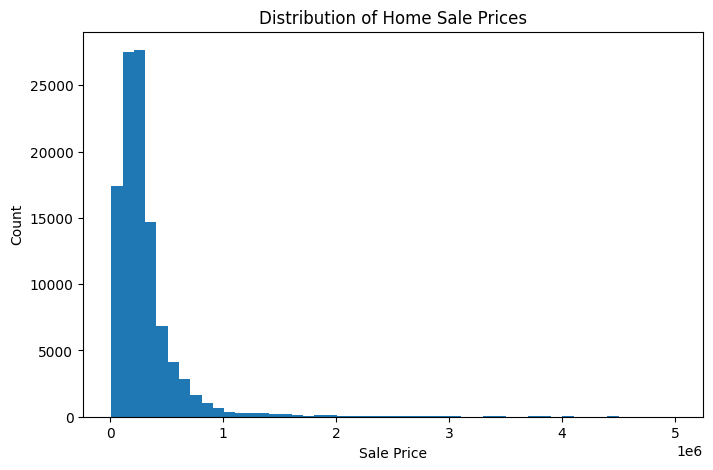

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(model_data["sale_price"], bins=50)
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.title("Distribution of Home Sale Prices")
plt.show()

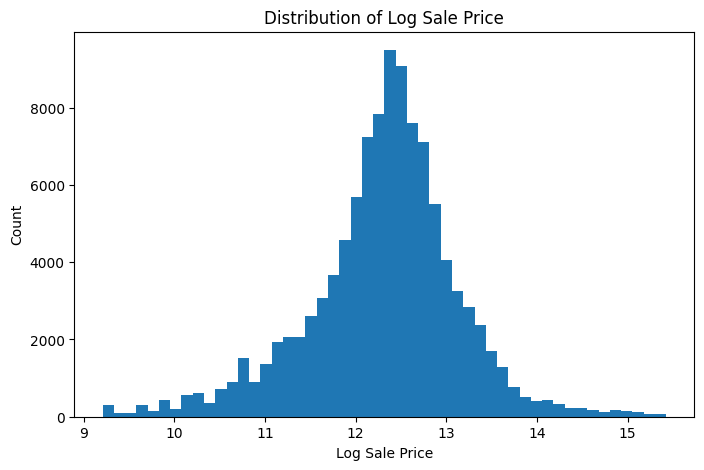

In [55]:
model_data["log_sale_price"] = np.log(model_data["sale_price"])

plt.figure(figsize=(8,5))
plt.hist(model_data["log_sale_price"], bins=50)
plt.xlabel("Log Sale Price")
plt.ylabel("Count")
plt.title("Distribution of Log Sale Price")
plt.show()

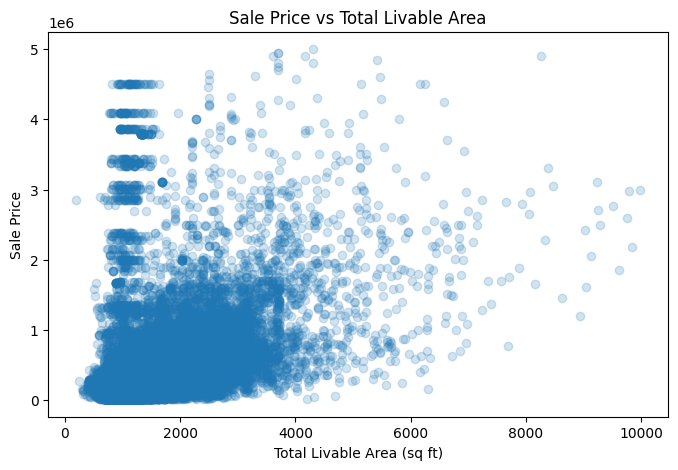

In [56]:
plt.figure(figsize=(8,5))

plot_data = model_data[
    model_data["total_livable_area"] <= 10000
]

plt.scatter(
    plot_data["total_livable_area"],
    plot_data["sale_price"],
    alpha=0.2
)

plt.xlabel("Total Livable Area (sq ft)")
plt.ylabel("Sale Price")
plt.title("Sale Price vs Total Livable Area")
plt.show()

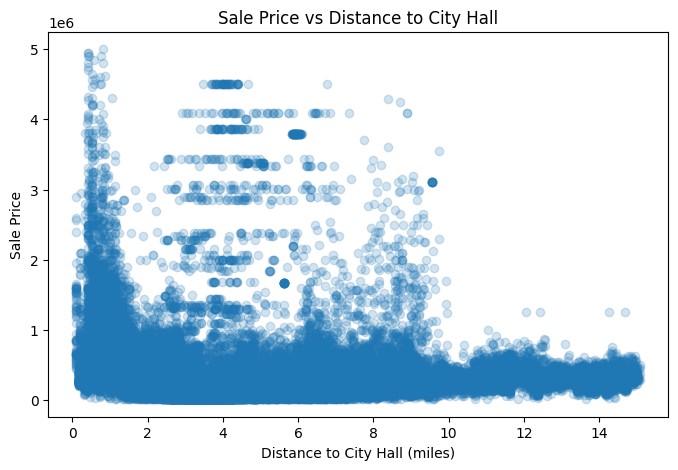

In [57]:
plt.figure(figsize=(8,5))
plt.scatter(
    model_data["distance_city_hall_miles"],
    model_data["sale_price"],
    alpha=0.2
)
plt.xlabel("Distance to City Hall (miles)")
plt.ylabel("Sale Price")
plt.title("Sale Price vs Distance to City Hall")
plt.show()

# Predictive Modeling

In [58]:
# Create time-related features

model_df = model_data.copy()

model_df["sale_year"] = model_df["sale_date"].dt.year
model_df["sale_month"] = model_df["sale_date"].dt.month

# Age of the house at the time of sale
model_df["house_age"] = (
    model_df["sale_year"] - model_df["year_built"]
)

model_df[
    ["sale_date", "sale_year", "sale_month", "year_built", "house_age"]
].head()

,sale_date,sale_year,sale_month,year_built,house_age
0,2026-08-20 04:00:00+00:00,2026,8,1925.0,101.0
1,2026-08-12 04:00:00+00:00,2026,8,1920.0,106.0
2,2026-08-03 04:00:00+00:00,2026,8,1925.0,101.0
3,2026-08-21 04:00:00+00:00,2026,8,1925.0,101.0
4,2026-08-21 04:00:00+00:00,2026,8,1964.0,62.0


In [59]:
features = [
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "interior_condition",
    "house_age",
    "zip_code",
    "median_household_income",
    "median_gross_rent",
    "owner_occupied_pct",
    "mortgage_rate",
    "distance_city_hall_miles",
    "sale_year",
    "sale_month"
]

X = model_df[features].copy()
y = model_df["sale_price"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (107321, 13)
y shape: (107321,)


,total_livable_area,number_of_bedrooms,number_of_bathrooms,interior_condition,house_age,zip_code,median_household_income,median_gross_rent,owner_occupied_pct,mortgage_rate,distance_city_hall_miles,sale_year,sale_month
0,1250.0,3.0,1.0,4.0,101.0,19138.0,52105.0,1072.0,53.901099,6.6675,6.384246,2026,8
1,812.0,3.0,1.0,4.0,106.0,19148.0,72167.0,1661.0,74.866943,6.6675,2.735864,2026,8
2,1166.0,3.0,1.0,4.0,101.0,19149.0,71777.0,1595.0,55.118790,6.6675,8.361613,2026,8
3,960.0,3.0,1.0,4.0,101.0,19143.0,36538.0,1532.0,53.179487,6.6675,3.345652,2026,8
4,1260.0,3.0,1.0,4.0,62.0,19114.0,84553.0,1495.0,69.347209,6.6675,12.412176,2026,8


In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 85856
Testing rows: 21465


In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [62]:
numeric_features = [
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "house_age",
    "median_household_income",
    "median_gross_rent",
    "owner_occupied_pct",
    "mortgage_rate",
    "distance_city_hall_miles",
    "sale_year"
]

categorical_features = [
    "interior_condition",
    "zip_code",
    "sale_month"
]

In [63]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [64]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [64]:
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['total_livable_area',
                                                   'number_of_bedrooms',
                                                   'number_of_bathrooms',
                                                   'house_age',
                                                   'median_household_income',
                                                   'median_gross_rent',
                                                   'owner_occupied_pct',
                                                   'mortgage_rate',
                                                   'distance_city_hall_miles',
                                                   'sale_year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['interior_condition',
                                                   'zip_code',
                                                   'sale_month'])])),
                ('model', LinearRegression())])

In [65]:
y_pred_linear = linear_model.predict(X_test)

In [66]:
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R²:", round(linear_r2, 4))

Linear Regression Results
MAE: 110936.42
RMSE: 282067.1
R²: 0.3855


In [67]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [68]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['total_livable_area',
                                                   'number_of_bedrooms',
                                                   'number_of_bathrooms',
                                                   'house_age',
                                                   'median_household_income',
                                                   'median_gross_rent',
                                                   'owner_occupied_pct',
                                                   'mortgage_rate',
                                                   'distance_city_hall_miles',
                                                   'sale_year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['interior_condition',
                                                   'zip_code',
                                                   'sale_month'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

In [69]:
y_pred_rf = rf_model.predict(X_test)

In [70]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²:", round(rf_r2, 4))

Random Forest Results
MAE: 76420.53
RMSE: 211110.88
R²: 0.6558


In [71]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R2": [linear_r2, rf_r2]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,110936.417196,282067.096042,0.385539
1,Random Forest,76420.527263,211110.878579,0.655800


In [72]:
# Check Random Forest performance on training data

y_train_pred_rf = rf_model.predict(X_train)

train_mae = mean_absolute_error(y_train, y_train_pred_rf)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
train_r2 = r2_score(y_train, y_train_pred_rf)

print("Random Forest - Training Results")
print("MAE:", round(train_mae, 2))
print("RMSE:", round(train_rmse, 2))
print("R²:", round(train_r2, 4))

print("\nRandom Forest - Testing Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²:", round(rf_r2, 4))

Random Forest - Training Results
MAE: 28292.86
RMSE: 77671.56
R²: 0.9528

Random Forest - Testing Results
MAE: 76420.53
RMSE: 211110.88
R²: 0.6558


In [69]:
from sklearn.ensemble import RandomForestRegressor

rf_tuned = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_tuned.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['total_livable_area',
                                                   'number_of_bedrooms',
                                                   'number_of_bathrooms',
                                                   'house_age',
                                                   'median_household_income',
                                                   'median_gross_rent',
                                                   'owner_occupied_pct',
                                                   'mortgage_rate',
                                                   'distance_city_hall_miles',
                                                   'sale_year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['interior_condition',
                                                   'zip_code',
                                                   'sale_month'])])),
                ('model',
                 RandomForestRegressor(max_depth=20, max_features=0.7,
                                       min_samples_leaf=5, min_samples_split=10,
                                       n_jobs=-1, random_state=42))])

In [74]:
# Predictions
y_train_pred_tuned = rf_tuned.predict(X_train)
y_test_pred_tuned = rf_tuned.predict(X_test)

# Training metrics
tuned_train_mae = mean_absolute_error(y_train, y_train_pred_tuned)
tuned_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_tuned))
tuned_train_r2 = r2_score(y_train, y_train_pred_tuned)

# Testing metrics
tuned_test_mae = mean_absolute_error(y_test, y_test_pred_tuned)
tuned_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_tuned))
tuned_test_r2 = r2_score(y_test, y_test_pred_tuned)

print("Tuned Random Forest - Training")
print("MAE:", round(tuned_train_mae, 2))
print("RMSE:", round(tuned_train_rmse, 2))
print("R²:", round(tuned_train_r2, 4))

print("\nTuned Random Forest - Testing")
print("MAE:", round(tuned_test_mae, 2))
print("RMSE:", round(tuned_test_rmse, 2))
print("R²:", round(tuned_test_r2, 4))

Tuned Random Forest - Training
MAE: 60418.82
RMSE: 167262.52
R²: 0.7809

Tuned Random Forest - Testing
MAE: 77290.35
RMSE: 210915.72
R²: 0.6564


In [75]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Test MAE": [
        linear_mae,
        rf_mae,
        tuned_test_mae
    ],
    "Test RMSE": [
        linear_rmse,
        rf_rmse,
        tuned_test_rmse
    ],
    "Test R2": [
        linear_r2,
        rf_r2,
        tuned_test_r2
    ]
})

comparison

,Model,Test MAE,Test RMSE,Test R2
0,Linear Regression,110936.417196,282067.096042,0.385539
1,Random Forest,76420.527263,211110.878579,0.655800
2,Tuned Random Forest,77290.352746,210915.719718,0.656436


# Time-Based Validation

In [76]:
# Time-based train/test split

train_time = model_df[model_df["sale_year"] <= 2024].copy()
test_time = model_df[model_df["sale_year"] >= 2025].copy()

X_train_time = train_time[features]
y_train_time = train_time["sale_price"]

X_test_time = test_time[features]
y_test_time = test_time["sale_price"]

print("Time-based training rows:", len(X_train_time))
print("Time-based testing rows:", len(X_test_time))

print("Training years:",
      train_time["sale_year"].min(),
      "-",
      train_time["sale_year"].max())

print("Testing years:",
      test_time["sale_year"].min(),
      "-",
      test_time["sale_year"].max())

Time-based training rows: 87039
Time-based testing rows: 20282
Training years: 2019 - 2024
Testing years: 2025 - 2026


In [77]:
from sklearn.base import clone

rf_time = clone(rf_model)

rf_time.fit(X_train_time, y_train_time)

y_pred_rf_time = rf_time.predict(X_test_time)

In [78]:
rf_time_mae = mean_absolute_error(
    y_test_time,
    y_pred_rf_time
)

rf_time_rmse = np.sqrt(
    mean_squared_error(
        y_test_time,
        y_pred_rf_time
    )
)

rf_time_r2 = r2_score(
    y_test_time,
    y_pred_rf_time
)

print("Random Forest - Time-Based Validation")
print("MAE:", round(rf_time_mae, 2))
print("RMSE:", round(rf_time_rmse, 2))
print("R²:", round(rf_time_r2, 4))

Random Forest - Time-Based Validation
MAE: 104938.68
RMSE: 326725.42
R²: 0.3923


In [79]:
rf_tuned_time = clone(rf_tuned)

rf_tuned_time.fit(
    X_train_time,
    y_train_time
)

y_pred_tuned_time = rf_tuned_time.predict(
    X_test_time
)

tuned_time_mae = mean_absolute_error(
    y_test_time,
    y_pred_tuned_time
)

tuned_time_rmse = np.sqrt(
    mean_squared_error(
        y_test_time,
        y_pred_tuned_time
    )
)

tuned_time_r2 = r2_score(
    y_test_time,
    y_pred_tuned_time
)

print("Tuned Random Forest - Time-Based Validation")
print("MAE:", round(tuned_time_mae, 2))
print("RMSE:", round(tuned_time_rmse, 2))
print("R²:", round(tuned_time_r2, 4))

Tuned Random Forest - Time-Based Validation
MAE: 104456.21
RMSE: 321773.99
R²: 0.4106


# Model Diagnostics

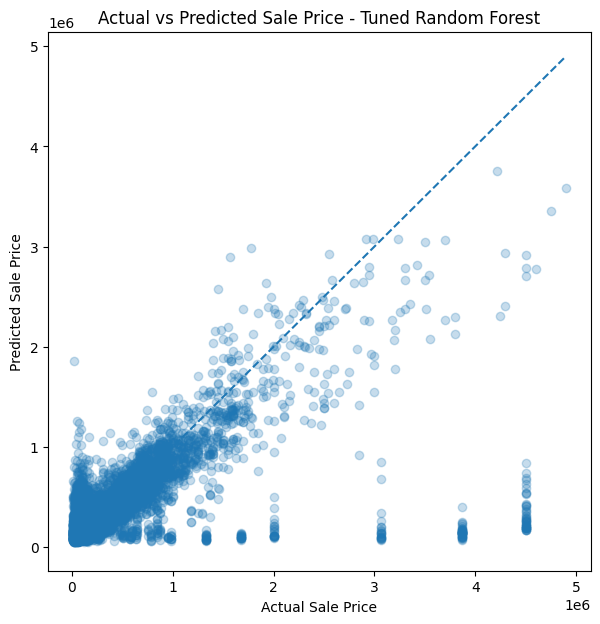

In [80]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test_time,
    y_pred_tuned_time,
    alpha=0.25
)

# Perfect prediction line
min_val = min(
    y_test_time.min(),
    y_pred_tuned_time.min()
)

max_val = max(
    y_test_time.max(),
    y_pred_tuned_time.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title(
    "Actual vs Predicted Sale Price - Tuned Random Forest"
)

plt.show()

In [81]:
# Feature importance from the tuned Random Forest

feature_names = (
    rf_tuned_time
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_tuned_time
    .named_steps["model"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

feature_importance.head(20)

,Feature,Importance
0,num__total_livable_area,0.309313
8,num__distance_city_hall_miles,0.231630
4,num__median_household_income,0.072457
3,num__house_age,0.052387
5,num__median_gross_rent,0.044543
2,num__number_of_bathrooms,0.041374
7,num__mortgage_rate,0.038198
20,cat__zip_code_19103.0,0.027572
9,num__sale_year,0.026613
6,num__owner_occupied_pct,0.024943


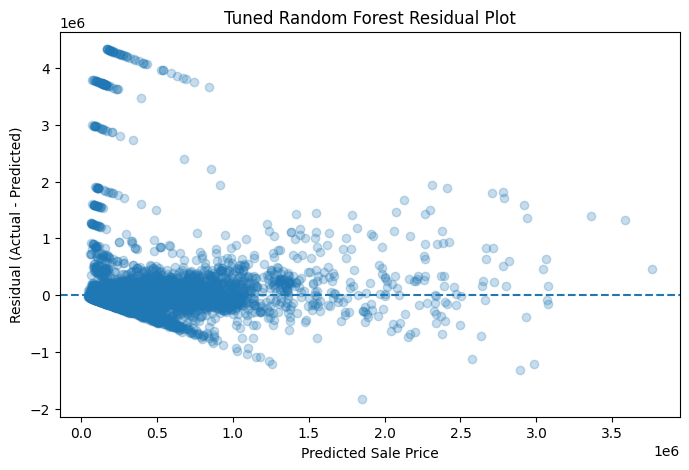

In [82]:
tuned_residuals = y_test_time - y_pred_tuned_time

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_tuned_time,
    tuned_residuals,
    alpha=0.25
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sale Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Tuned Random Forest Residual Plot")

plt.show()

In [83]:
pd.Series(tuned_residuals).describe()

,sale_price
count,2.028200e+04
mean,2.070424e+04
std,3.211151e+05
min,-1.834476e+06
25%,-5.579147e+04
50%,4.884695e+02
75%,4.454851e+04
max,4.330448e+06


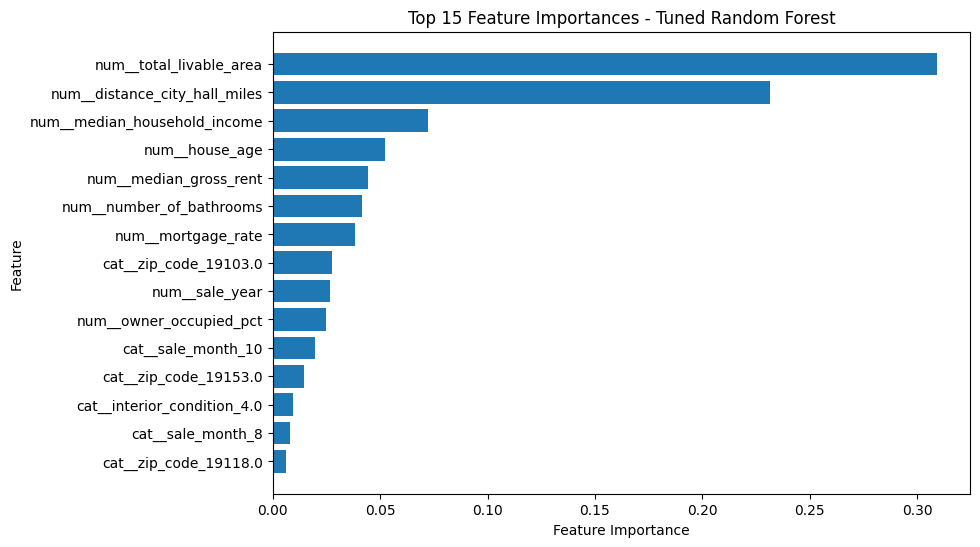

In [84]:
top_features = (
    feature_importance
    .head(15)
    .sort_values("Importance")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top 15 Feature Importances - Tuned Random Forest"
)

plt.show()

In [85]:
from sklearn.base import clone

linear_time = clone(linear_model)

linear_time.fit(X_train_time, y_train_time)

y_pred_linear_time = linear_time.predict(X_test_time)

linear_time_mae = mean_absolute_error(
    y_test_time, y_pred_linear_time
)

linear_time_rmse = np.sqrt(
    mean_squared_error(
        y_test_time, y_pred_linear_time
    )
)

linear_time_r2 = r2_score(
    y_test_time, y_pred_linear_time
)

print("Linear Regression - Time-Based Validation")
print("MAE:", round(linear_time_mae, 2))
print("RMSE:", round(linear_time_rmse, 2))
print("R²:", round(linear_time_r2, 4))

Linear Regression - Time-Based Validation
MAE: 135692.03
RMSE: 344894.65
R²: 0.3229


In [86]:
time_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Time-Based MAE": [
        linear_time_mae,
        rf_time_mae,
        tuned_time_mae
    ],
    "Time-Based RMSE": [
        linear_time_rmse,
        rf_time_rmse,
        tuned_time_rmse
    ],
    "Time-Based R2": [
        linear_time_r2,
        rf_time_r2,
        tuned_time_r2
    ]
})

time_comparison

,Model,Time-Based MAE,Time-Based RMSE,Time-Based R2
0,Linear Regression,135692.030143,344894.645304,0.322866
1,Random Forest,104938.675738,326725.417271,0.392331
2,Tuned Random Forest,104456.213903,321773.992761,0.410609


# Deployment-Friendly Model

In [87]:
ui_features = [
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "interior_condition",
    "house_age",
    "zip_code",
    "sale_year",
    "sale_month"
]

X_ui = model_df[ui_features].copy()
y_ui = model_df["sale_price"].copy()

In [88]:
train_ui = model_df[model_df["sale_year"] <= 2024].copy()
test_ui = model_df[model_df["sale_year"] >= 2025].copy()

X_train_ui = train_ui[ui_features]
y_train_ui = train_ui["sale_price"]

X_test_ui = test_ui[ui_features]
y_test_ui = test_ui["sale_price"]

print("Training rows:", len(X_train_ui))
print("Testing rows:", len(X_test_ui))

Training rows: 87039
Testing rows: 20282


In [89]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

ui_numeric_features = [
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "house_age",
    "sale_year"
]

ui_categorical_features = [
    "interior_condition",
    "zip_code",
    "sale_month"
]

ui_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ui_numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ui_categorical_features)
    ]
)

In [90]:
ui_rf_model = Pipeline(
    steps=[
        ("preprocessor", ui_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [91]:
ui_rf_model.fit(X_train_ui, y_train_ui)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['total_livable_area',
                                                   'number_of_bedrooms',
                                                   'number_of_bathrooms',
                                                   'house_age', 'sale_year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['interior_condition',
                                                   'zip_code',
                                                   'sale_month'])])),
                ('model',
                 RandomForestRegressor(max_depth=20, max_features=0.7,
                                       min_samples_leaf=5, min_samples_split=10,
                                       n_jobs=-1, random_state=42))])

In [92]:
y_pred_ui = ui_rf_model.predict(X_test_ui)

ui_mae = mean_absolute_error(y_test_ui, y_pred_ui)
ui_rmse = np.sqrt(mean_squared_error(y_test_ui, y_pred_ui))
ui_r2 = r2_score(y_test_ui, y_pred_ui)

print("Deployment-Friendly Random Forest")
print("MAE:", round(ui_mae, 2))
print("RMSE:", round(ui_rmse, 2))
print("R²:", round(ui_r2, 4))

Deployment-Friendly Random Forest
MAE: 144865.54
RMSE: 359839.39
R²: 0.2629


In [93]:
deployment_comparison = pd.DataFrame({
    "Model": [
        "Full Tuned Random Forest",
        "Deployment-Friendly Random Forest"
    ],
    "MAE": [
        tuned_time_mae,
        ui_mae
    ],
    "RMSE": [
        tuned_time_rmse,
        ui_rmse
    ],
    "R2": [
        tuned_time_r2,
        ui_r2
    ]
})

deployment_comparison

,Model,MAE,RMSE,R2
0,Full Tuned Random Forest,104456.213903,321773.992761,0.410609
1,Deployment-Friendly Random Forest,144865.536490,359839.387529,0.262913


# Final Model for Deployment

In [70]:
from sklearn.base import clone

final_model = clone(rf_tuned)

final_model.fit(X, y)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['total_livable_area',
                                                   'number_of_bedrooms',
                                                   'number_of_bathrooms',
                                                   'house_age',
                                                   'median_household_income',
                                                   'median_gross_rent',
                                                   'owner_occupied_pct',
                                                   'mortgage_rate',
                                                   'distance_city_hall_miles',
                                                   'sale_year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['interior_condition',
                                                   'zip_code',
                                                   'sale_month'])])),
                ('model',
                 RandomForestRegressor(max_depth=20, max_features=0.7,
                                       min_samples_leaf=5, min_samples_split=10,
                                       n_jobs=-1, random_state=42))])

In [71]:
import joblib

joblib.dump(
    final_model,
    "philadelphia_house_price_model_compressed.joblib",
    compress=3
)

print("Compressed model saved.")

Compressed model saved.


In [72]:
import os

compressed_size = os.path.getsize(
    "philadelphia_house_price_model_compressed.joblib"
) / (1024**2)

print("Compressed model size:", round(compressed_size, 2), "MB")

Compressed model size: 30.64 MB


In [73]:
loaded_model = joblib.load(
    "philadelphia_house_price_model_compressed.joblib"
)

print("Model loaded successfully.")

Model loaded successfully.


In [74]:
sample_houses = X.head(5)

sample_predictions = loaded_model.predict(sample_houses)

pd.DataFrame({
    "Actual Price": y.head(5).values,
    "Predicted Price": sample_predictions
})

,Actual Price,Predicted Price
0,107700.0,145567.268143
1,209999.0,218256.674526
2,243500.0,238435.063841
3,75000.0,107914.929118
4,310000.0,306349.988507


In [75]:
original_predictions = final_model.predict(sample_houses)
loaded_predictions = loaded_model.predict(sample_houses)

print(
    np.allclose(
        original_predictions,
        loaded_predictions
    )
)

True


# Website Deployment Files

In [76]:
import json

deployment_info = {
    "model_features": features,
    "user_inputs": [
        "total_livable_area",
        "number_of_bedrooms",
        "number_of_bathrooms",
        "interior_condition",
        "year_built",
        "property_location"
    ],
    "automatically_generated": [
        "house_age",
        "zip_code",
        "median_household_income",
        "median_gross_rent",
        "owner_occupied_pct",
        "mortgage_rate",
        "distance_city_hall_miles",
        "sale_year",
        "sale_month"
    ]
}

with open("deployment_info.json", "w") as f:
    json.dump(deployment_info, f, indent=4)

print("Deployment info saved.")

Deployment info saved.


In [77]:
# Create a complete Census tract lookup for deployment

deployment_tract_lookup = census[
    [
        "GEOID",
        "median_household_income",
        "median_gross_rent",
        "owner_occupied_pct"
    ]
].copy()

print("Total census tracts:", len(deployment_tract_lookup))

print("\nMissing values before filling:")
print(
    deployment_tract_lookup[
        [
            "median_household_income",
            "median_gross_rent",
            "owner_occupied_pct"
        ]
    ].isna().sum()
)

Total census tracts: 408

Missing values before filling:
median_household_income    33
median_gross_rent          25
owner_occupied_pct         19
dtype: int64


In [78]:
# Median fallback values based on the model training data

income_fallback = model_data["median_household_income"].median()
rent_fallback = model_data["median_gross_rent"].median()
owner_fallback = model_data["owner_occupied_pct"].median()

deployment_tract_lookup["median_household_income"] = (
    deployment_tract_lookup["median_household_income"]
    .fillna(income_fallback)
)

deployment_tract_lookup["median_gross_rent"] = (
    deployment_tract_lookup["median_gross_rent"]
    .fillna(rent_fallback)
)

deployment_tract_lookup["owner_occupied_pct"] = (
    deployment_tract_lookup["owner_occupied_pct"]
    .fillna(owner_fallback)
)

print("\nMissing values after filling:")
print(
    deployment_tract_lookup[
        [
            "median_household_income",
            "median_gross_rent",
            "owner_occupied_pct"
        ]
    ].isna().sum()
)

print("\nNumber of tracts:", len(deployment_tract_lookup))


Missing values after filling:
median_household_income    0
median_gross_rent          0
owner_occupied_pct         0
dtype: int64

Number of tracts: 408


In [79]:
deployment_tract_lookup["GEOID"] = (
    deployment_tract_lookup["GEOID"].astype(str)
)

deployment_tract_lookup.to_csv(
    "philadelphia_census_tract_lookup_complete.csv",
    index=False
)

print(deployment_tract_lookup.dtypes)

GEOID                       object
median_household_income    float64
median_gross_rent          float64
owner_occupied_pct         float64
dtype: object


In [80]:
fred_monthly_export = fred_monthly.copy()

fred_monthly_export["sale_month"] = (
    fred_monthly_export["sale_month"].astype(str)
)

fred_monthly_export.to_csv(
    "mortgage_rate_monthly_lookup.csv",
    index=False
)

print("Mortgage lookup saved.")
print(fred_monthly_export.tail())

Mortgage lookup saved.
    sale_month  mortgage_rate
662    2026-06         6.4900
663    2026-07         6.5420
664    2026-08         6.6675
665    2026-09         6.8625
666    2026-10         7.3600


# Create Deployment Files

In [81]:
%%writefile model_backend.py

import math
import joblib
import requests
import pandas as pd

from pyproj import Transformer


# --------------------------------------------------
# Files
# --------------------------------------------------

MODEL_FILE = "philadelphia_house_price_model_compressed.joblib"
TRACT_FILE = "philadelphia_census_tract_lookup_complete.csv"
MORTGAGE_FILE = "mortgage_rate_monthly_lookup.csv"


# --------------------------------------------------
# Load model and lookup tables
# --------------------------------------------------

model = joblib.load(MODEL_FILE)

tract_lookup = pd.read_csv(
    TRACT_FILE,
    dtype={"GEOID": str}
)

mortgage_lookup = pd.read_csv(
    MORTGAGE_FILE
)

mortgage_lookup["sale_month"] = pd.PeriodIndex(
    mortgage_lookup["sale_month"],
    freq="M"
)


# --------------------------------------------------
# Model features
# --------------------------------------------------

MODEL_FEATURES = [
    "total_livable_area",
    "number_of_bedrooms",
    "number_of_bathrooms",
    "interior_condition",
    "house_age",
    "zip_code",
    "median_household_income",
    "median_gross_rent",
    "owner_occupied_pct",
    "mortgage_rate",
    "distance_city_hall_miles",
    "sale_year",
    "sale_month"
]


# --------------------------------------------------
# City Hall coordinates
# --------------------------------------------------

CITY_HALL_LONGITUDE = -75.1636
CITY_HALL_LATITUDE = 39.9526

transformer_to_2272 = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:2272",
    always_xy=True
)


# --------------------------------------------------
# Mortgage Rate
# --------------------------------------------------

def get_mortgage_rate_for_date(prediction_date):

    prediction_date = pd.to_datetime(prediction_date)

    if prediction_date.tzinfo is not None:
        prediction_date = prediction_date.tz_localize(None)

    prediction_month = prediction_date.to_period("M")

    available_rates = mortgage_lookup[
        mortgage_lookup["sale_month"] <= prediction_month
    ].sort_values("sale_month")

    if available_rates.empty:
        raise ValueError(
            "No mortgage rate available for this date."
        )

    return available_rates.iloc[-1]["mortgage_rate"]


# --------------------------------------------------
# Address → location
# --------------------------------------------------

def get_location_info(address):

    url = (
        "https://geocoding.geo.census.gov/"
        "geocoder/geographies/onelineaddress"
    )

    params = {
        "address": address,
        "benchmark": "Public_AR_Current",
        "vintage": "Current_Current",
        "format": "json"
    }

    response = requests.get(
        url,
        params=params,
        timeout=20
    )

    response.raise_for_status()

    data = response.json()

    matches = data["result"]["addressMatches"]

    if len(matches) == 0:
        raise ValueError(
            "Address could not be found."
        )

    match = matches[0]

    latitude = match["coordinates"]["y"]
    longitude = match["coordinates"]["x"]

    zip_code = match["addressComponents"]["zip"]

    geographies = match["geographies"]

    census_tract = geographies[
        "Census Tracts"
    ][0]

    geoid = census_tract["GEOID"]

    return {
        "latitude": latitude,
        "longitude": longitude,
        "zip_code": zip_code,
        "GEOID": geoid
    }


# --------------------------------------------------
# City Hall distance
# --------------------------------------------------

def calculate_city_hall_distance(
    latitude,
    longitude
):

    property_x, property_y = transformer_to_2272.transform(
        longitude,
        latitude
    )

    city_hall_x, city_hall_y = transformer_to_2272.transform(
        CITY_HALL_LONGITUDE,
        CITY_HALL_LATITUDE
    )

    distance_feet = math.sqrt(
        (property_x - city_hall_x) ** 2
        +
        (property_y - city_hall_y) ** 2
    )

    return distance_feet / 5280


# --------------------------------------------------
# Model prediction
# --------------------------------------------------

def predict_house_price(
    living_area,
    bedrooms,
    bathrooms,
    interior_condition,
    year_built,
    zip_code,
    geoid,
    distance_city_hall_miles,
    prediction_date=None
):

    if prediction_date is None:
        prediction_date = pd.Timestamp.today()
    else:
        prediction_date = pd.to_datetime(
            prediction_date
        )

    sale_year = prediction_date.year
    sale_month = prediction_date.month

    if year_built > sale_year:
        raise ValueError(
            "Year built cannot be after the prediction year."
        )

    house_age = sale_year - year_built

    mortgage_rate = get_mortgage_rate_for_date(
        prediction_date
    )

    tract_row = tract_lookup[
        tract_lookup["GEOID"] == str(geoid)
    ]

    if tract_row.empty:
        raise ValueError(
            "Census tract is not available in the Philadelphia lookup."
        )

    tract_row = tract_row.iloc[0]

    house = pd.DataFrame([{
        "total_livable_area":
            living_area,

        "number_of_bedrooms":
            bedrooms,

        "number_of_bathrooms":
            bathrooms,

        "interior_condition":
            interior_condition,

        "house_age":
            house_age,

        "zip_code":
            float(zip_code),

        "median_household_income":
            tract_row["median_household_income"],

        "median_gross_rent":
            tract_row["median_gross_rent"],

        "owner_occupied_pct":
            tract_row["owner_occupied_pct"],

        "mortgage_rate":
            mortgage_rate,

        "distance_city_hall_miles":
            distance_city_hall_miles,

        "sale_year":
            sale_year,

        "sale_month":
            sale_month
    }])

    house = house[MODEL_FEATURES]

    prediction = model.predict(house)[0]

    return float(prediction)


# --------------------------------------------------
# Complete website prediction
# --------------------------------------------------

def predict_price_from_address(
    address,
    living_area,
    bedrooms,
    bathrooms,
    interior_condition,
    year_built,
    prediction_date=None
):

    location = get_location_info(
        address
    )

    geoid = str(
        location["GEOID"]
    )

    if not geoid.startswith("42101"):
        raise ValueError(
            "This model is designed for Philadelphia properties only."
        )

    distance = calculate_city_hall_distance(
        latitude=location["latitude"],
        longitude=location["longitude"]
    )

    predicted_price = predict_house_price(
        living_area=living_area,
        bedrooms=bedrooms,
        bathrooms=bathrooms,
        interior_condition=interior_condition,
        year_built=year_built,
        zip_code=location["zip_code"],
        geoid=geoid,
        distance_city_hall_miles=distance,
        prediction_date=prediction_date
    )

    return {
        "predicted_price":
            float(predicted_price),

        "zip_code":
            location["zip_code"],

        "GEOID":
            geoid,

        "distance_city_hall_miles":
            float(distance)
    }

Writing model_backend.py


In [82]:
import importlib
import model_backend

importlib.reload(model_backend)

backend_test = model_backend.predict_price_from_address(
    address="1400 John F Kennedy Blvd, Philadelphia, PA 19107",
    living_area=1500,
    bedrooms=3,
    bathrooms=2,
    interior_condition=4,
    year_built=1950
)

backend_test

{'predicted_price': 596580.1838009766,
 'zip_code': '19107',
 'GEOID': '42101000500',
 'distance_city_hall_miles': 0.04995435125678016}

In [83]:
%%writefile requirements.txt

pandas
numpy
scikit-learn
joblib
requests
pyproj

Writing requirements.txt


In [84]:
%%writefile README.txt

Philadelphia House Price Prediction - Deployment Package

Files:
1. philadelphia_house_price_model_compressed.joblib
   - Final trained Tuned Random Forest model

2. philadelphia_census_tract_lookup_complete.csv
   - Philadelphia Census tract socioeconomic lookup data

3. mortgage_rate_monthly_lookup.csv
   - Monthly 30-year mortgage rate lookup data

4. deployment_info.json
   - Model feature and input information

5. model_backend.py
   - Backend functions for address lookup and house price prediction

6. requirements.txt
   - Required Python packages


Main website function:

from model_backend import predict_price_from_address


Example:

result = predict_price_from_address(
    address="1400 John F Kennedy Blvd, Philadelphia, PA 19107",
    living_area=1500,
    bedrooms=3,
    bathrooms=2,
    interior_condition=4,
    year_built=1950
)

print(result["predicted_price"])


User-facing inputs:
- Property address
- Living area
- Bedrooms
- Bathrooms
- Interior condition
- Year built

The backend automatically determines:
- ZIP code
- Census tract
- Census variables
- Distance to Philadelphia City Hall
- Prediction year/month
- Mortgage rate

Scope:
This model is designed for Philadelphia properties only.

Overwriting README.txt


In [85]:
import zipfile
import os

files_to_package = [
    "philadelphia_house_price_model_compressed.joblib",
    "philadelphia_census_tract_lookup_complete.csv",
    "mortgage_rate_monthly_lookup.csv",
    "deployment_info.json",
    "model_backend.py",
    "requirements.txt",
    "README.txt"
]

zip_name = "philadelphia_house_price_deployment.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file in files_to_package:
        zipf.write(file)
        print("Added:", file)

print("\nFinal ZIP created.")
print(
    "ZIP size:",
    round(
        os.path.getsize(zip_name) / (1024**2),
        2
    ),
    "MB"
)

Added: philadelphia_house_price_model_compressed.joblib
Added: philadelphia_census_tract_lookup_complete.csv
Added: mortgage_rate_monthly_lookup.csv
Added: deployment_info.json
Added: model_backend.py
Added: requirements.txt
Added: README.txt

Final ZIP created.
ZIP size: 30.34 MB


# Independent Deployment Test

In [86]:
import os
import zipfile
import shutil

test_folder = "deployment_test"

# Remove old test folder if it already exists
if os.path.exists(test_folder):
    shutil.rmtree(test_folder)

os.makedirs(test_folder)

with zipfile.ZipFile(
    "philadelphia_house_price_deployment.zip",
    "r"
) as zipf:
    zipf.extractall(test_folder)

print("Files extracted:")
print(os.listdir(test_folder))

Files extracted:
['README.txt', 'model_backend.py', 'philadelphia_census_tract_lookup_complete.csv', 'mortgage_rate_monthly_lookup.csv', 'requirements.txt', 'philadelphia_house_price_model_compressed.joblib', 'deployment_info.json']


In [87]:
import subprocess
import sys

test_code = """
from model_backend import predict_price_from_address

result = predict_price_from_address(
    address="1400 John F Kennedy Blvd, Philadelphia, PA 19107",
    living_area=1500,
    bedrooms=3,
    bathrooms=2,
    interior_condition=4,
    year_built=1950
)

print(result)
"""

result = subprocess.run(
    [sys.executable, "-c", test_code],
    cwd=test_folder,
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)

print("\nOUTPUT:")
print(result.stdout)

if result.stderr:
    print("\nERROR:")
    print(result.stderr)

RETURN CODE: 0

OUTPUT:
{'predicted_price': 596580.1838009765, 'zip_code': '19107', 'GEOID': '42101000500', 'distance_city_hall_miles': 0.04995435125678016}



# AI Use Log

| Date | Tool or Skill | Narrow Task | Prompt or Concise Summary | What I Changed | How I Verified the Result |
|---|---|---|---|---|---|
| 2026-10-13 | ChatGPT | Data-cleaning code assistance | Asked for help checking Python syntax for filtering Philadelphia property records and removing invalid or unusable observations. | Revised filtering code for sale dates, sale-price limits, property characteristics, and missing values. | I reran the cleaning cells and checked the resulting row counts, missing values, and variable ranges. |
| 2026-10-13 | ChatGPT | Census and geographic-data coding assistance | Asked for help with Python syntax for joining property data to Philadelphia Census tracts and adding ACS variables. | Used spatial-join code and merged Census tract variables such as median household income, median gross rent, and owner-occupied percentage. | I checked the number of matched properties, inspected GEOID values, and confirmed the merged variables appeared in the final modeling dataset. |
| 2026-10-13 | ChatGPT | External-variable coding assistance | Asked for help writing Python code to add monthly mortgage rates and calculate distance from each property to Philadelphia City Hall. | Added monthly mortgage-rate matching and geographic-distance calculations to the modeling dataset. | I inspected sample rows and tested the distance calculation and mortgage-rate lookup for known dates and locations. |
| 2026-10-13 | ChatGPT | Model-building syntax assistance | Asked for Python syntax to prepare numeric and categorical predictors and compare Linear Regression and Random Forest models. | Built preprocessing pipelines, created train/test data, fit the models, and calculated MAE, RMSE, and R-squared. | I ran all model cells myself and checked that each model returned predictions and evaluation metrics without errors. |
| 2026-10-14 | ChatGPT | Random Forest tuning code assistance | Asked for help modifying Random Forest parameters to reduce overfitting while keeping the same modeling approach. | Created a tuned Random Forest with limits on tree depth, minimum samples, and feature selection. | I compared training and testing metrics before and after the parameter changes and reran the model successfully. |
| 2026-10-14 | ChatGPT | Time-based validation code assistance | Asked for help writing code to evaluate the models using earlier years for training and 2025–2026 observations for testing. | Added a time-based train/test split and evaluated Linear Regression, Random Forest, and Tuned Random Forest using the same metrics. | I checked the training and testing year ranges and verified the MAE, RMSE, and R-squared outputs for all models. |
| 2026-10-15 | ChatGPT | Website-backend coding assistance | Asked for help organizing Python functions so a user could enter an address and housing characteristics while contextual variables were retrieved automatically. | Created backend functions for address geocoding, Census tract lookup, mortgage-rate lookup, City Hall distance, and model prediction. | I tested the functions with a Philadelphia address and compared the backend prediction with the model prediction. |
| 2026-10-15 | ChatGPT | Deployment debugging and packaging | Asked for help checking the deployment files, fixing Python data-type issues, and packaging the model and supporting files. | Converted prediction outputs to standard Python floats, created `requirements.txt`, a README, lookup files, and the deployment ZIP. | I extracted the ZIP into a separate folder and ran the backend in a new Python subprocess. The test completed with return code 0. |
| 2026-10-16 | ChatGPT | Notebook code cleanup | Asked ChatGPT to review the working notebook for duplicate or outdated code without changing the analysis. | Removed duplicate prototype functions, old model-save cells, an outdated Census lookup, an older backend version, and an incomplete deployment ZIP cell. | I reviewed each suggested deletion individually and kept the final working versions of the model, backend, lookup files, and deployment package. |
| 2026-10-16 | ChatGPT | Update model diagnostic code | Asked ChatGPT to identify diagnostic code that still used the original Random Forest and suggest the smallest changes needed to match the tuned time-based model. | Updated the Actual vs. Predicted plot, feature-importance calculation, feature-importance chart, residual plot, and residual summary to use the tuned time-based Random Forest. | I ran each revised cell myself and confirmed that all plots and summary tables were produced without errors. |